Using device: cuda


100%|██████████| 170M/170M [28:47<00:00, 98.7kB/s]


Train images: 50000 | Test images: 10000
Text vocab size: 19 | Max caption length: 5


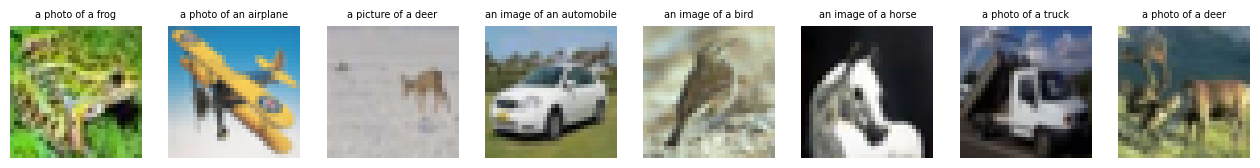

In [ ]:
# CELL 1 (CIFAR 10): Setup, data and captions
import random
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

transform = transforms.ToTensor()   # CIFAR 10 is already 32x32 colour, so no padding
train_base = datasets.CIFAR10("data", train=True, download=True, transform=transform)
test_base = datasets.CIFAR10("data", train=False, download=True, transform=transform)

CLASS_PHRASES = ["an airplane", "an automobile", "a bird", "a cat", "a deer",
                 "a dog", "a frog", "a horse", "a ship", "a truck"]
TEMPLATES = ["a photo of {}", "an image of {}", "a picture of {}", "this is {}"]

all_captions = [t.format(c) for t in TEMPLATES for c in CLASS_PHRASES]
vocab = ["<pad>"] + sorted({w for cap in all_captions for w in cap.split()})
word2id = {w: i for i, w in enumerate(vocab)}
MAX_TEXT_LEN = max(len(cap.split()) for cap in all_captions)
TEXT_VOCAB_SIZE = len(vocab)

def encode_caption(text):
    ids = [word2id[w] for w in text.split()]
    ids += [0] * (MAX_TEXT_LEN - len(ids))
    return torch.tensor(ids)

class CaptionedDataset(Dataset):
    """Returns (image, caption token ids, class label). Caption template is random each time."""
    def __init__(self, base):
        self.base = base
    def __len__(self):
        return len(self.base)
    def __getitem__(self, i):
        img, label = self.base[i]
        caption = random.choice(TEMPLATES).format(CLASS_PHRASES[label])
        return img, encode_caption(caption), label

train_ds = CaptionedDataset(train_base)
test_ds = CaptionedDataset(test_base)
train_loader = DataLoader(train_ds, batch_size=128, shuffle=True, num_workers=0)
test_loader = DataLoader(test_ds, batch_size=128, shuffle=False, num_workers=0)

print("Train images:", len(train_ds), "| Test images:", len(test_ds))
print("Text vocab size:", TEXT_VOCAB_SIZE, "| Max caption length:", MAX_TEXT_LEN)

imgs, caps, labels = next(iter(train_loader))
fig, axes = plt.subplots(1, 8, figsize=(16, 2.4))
for ax, im, cp in zip(axes, imgs, caps):
    ax.imshow(im.permute(1, 2, 0)); ax.axis("off")
    ax.set_title(" ".join(vocab[t] for t in cp if t != 0), fontsize=7)
plt.show()

In [ ]:
# CELL 2 (CIFAR 10): Discrete VAE
import math
import torch.nn as nn
import torch.nn.functional as F

NUM_CODES = 256             # bigger image vocabulary for colour
GRID = 8
IMG_SEQ_LEN = GRID * GRID

class DVAE(nn.Module):
    def __init__(self, num_codes=NUM_CODES, hidden=128):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(3, hidden, 4, stride=2, padding=1), nn.ReLU(),
            nn.Conv2d(hidden, hidden, 4, stride=2, padding=1), nn.ReLU(),
            nn.Conv2d(hidden, hidden, 3, padding=1), nn.ReLU(),
            nn.Conv2d(hidden, num_codes, 1))
        self.codebook = nn.Embedding(num_codes, hidden)
        self.decoder = nn.Sequential(
            nn.Conv2d(hidden, hidden, 3, padding=1), nn.ReLU(),
            nn.ConvTranspose2d(hidden, hidden, 4, stride=2, padding=1), nn.ReLU(),
            nn.ConvTranspose2d(hidden, 3, 4, stride=2, padding=1), nn.Sigmoid())

    def forward(self, x, temperature):
        logits = self.encoder(x)
        soft = F.gumbel_softmax(logits, tau=temperature, dim=1)
        z = torch.einsum("bkhw,kd->bdhw", soft, self.codebook.weight)
        return self.decoder(z), logits

    @torch.no_grad()
    def get_tokens(self, x):
        return self.encoder(x).argmax(dim=1).flatten(1)

    @torch.no_grad()
    def decode_tokens(self, tokens):
        B = tokens.shape[0]
        z = self.codebook(tokens).view(B, GRID, GRID, -1).permute(0, 3, 1, 2)
        return self.decoder(z)

print("Parameters:", sum(p.numel() for p in DVAE().parameters()))

Parameters: 897923


dVAE epoch 1/20  reconstruction MSE: 0.01669
dVAE epoch 2/20  reconstruction MSE: 0.00742
dVAE epoch 3/20  reconstruction MSE: 0.00586
dVAE epoch 4/20  reconstruction MSE: 0.00545
dVAE epoch 5/20  reconstruction MSE: 0.00517
dVAE epoch 6/20  reconstruction MSE: 0.00496
dVAE epoch 7/20  reconstruction MSE: 0.00479
dVAE epoch 8/20  reconstruction MSE: 0.00468
dVAE epoch 9/20  reconstruction MSE: 0.00461
dVAE epoch 10/20  reconstruction MSE: 0.00458
dVAE epoch 11/20  reconstruction MSE: 0.00456
dVAE epoch 12/20  reconstruction MSE: 0.00453
dVAE epoch 13/20  reconstruction MSE: 0.00453
dVAE epoch 14/20  reconstruction MSE: 0.00454
dVAE epoch 15/20  reconstruction MSE: 0.00452
dVAE epoch 16/20  reconstruction MSE: 0.00457
dVAE epoch 17/20  reconstruction MSE: 0.00455
dVAE epoch 18/20  reconstruction MSE: 0.00458
dVAE epoch 19/20  reconstruction MSE: 0.00462
dVAE epoch 20/20  reconstruction MSE: 0.00470
Test MSE: 0.005074916873127222
Codes used in these 16 images (out of 256 ): 205


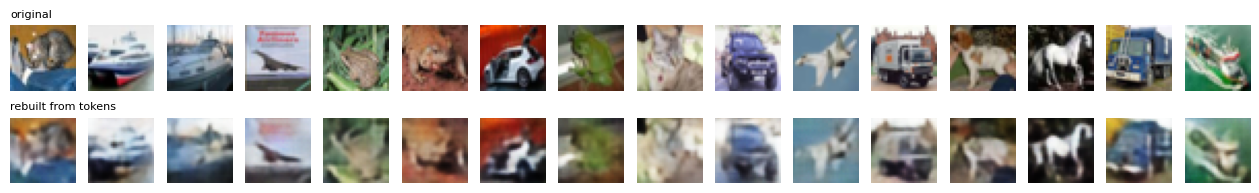

In [ ]:
# CELL 3 (CIFAR 10): Train the dVAE, then check reconstructions
dvae = DVAE().to(device)
opt_d = torch.optim.Adam(dvae.parameters(), lr=0.001)
EPOCHS_DVAE = 20
TEMP_START, TEMP_END = 1.0, 0.1
KL_WEIGHT = 0.0005
total_steps = EPOCHS_DVAE * len(train_loader)
step = 0

for epoch in range(EPOCHS_DVAE):
    dvae.train()
    running = 0.0
    for imgs, _, _ in train_loader:
        imgs = imgs.to(device)
        temp = TEMP_START + (TEMP_END - TEMP_START) * step / total_steps
        recon, logits = dvae(imgs, temp)
        recon_loss = F.mse_loss(recon, imgs)
        log_q = F.log_softmax(logits, dim=1)
        kl = (log_q.exp() * (log_q + math.log(NUM_CODES))).sum(dim=1).mean()
        loss = recon_loss + KL_WEIGHT * kl
        opt_d.zero_grad(); loss.backward(); opt_d.step()
        running += recon_loss.item(); step += 1
    print(f"dVAE epoch {epoch + 1}/{EPOCHS_DVAE}  reconstruction MSE: {running / len(train_loader):.5f}")

dvae.eval()
test_imgs = torch.stack([test_base[i][0] for i in range(16)]).to(device)
tokens = dvae.get_tokens(test_imgs)
recon = dvae.decode_tokens(tokens)
print("Test MSE:", F.mse_loss(recon, test_imgs).item())
print("Codes used in these 16 images (out of", NUM_CODES, "):", tokens.unique().numel())

fig, axes = plt.subplots(2, 16, figsize=(16, 2.2))
for i in range(16):
    axes[0, i].imshow(test_imgs[i].permute(1, 2, 0).cpu()); axes[0, i].axis("off")
    axes[1, i].imshow(recon[i].permute(1, 2, 0).cpu()); axes[1, i].axis("off")
axes[0, 0].set_title("original", fontsize=8, loc="left")
axes[1, 0].set_title("rebuilt from tokens", fontsize=8, loc="left")
plt.show()

In [ ]:
# CELL 4: The DALL-E style transformer, and the dataset turned into tokens
class MiniDALLE(nn.Module):
    def __init__(self, dim=256, depth=4, heads=4, dropout=0.1):
        super().__init__()
        self.total_vocab = TEXT_VOCAB_SIZE + NUM_CODES      # text words and image codes share one vocabulary
        self.seq_len = MAX_TEXT_LEN + IMG_SEQ_LEN
        self.tok_emb = nn.Embedding(self.total_vocab, dim)
        self.pos_emb = nn.Embedding(self.seq_len, dim)
        layer = nn.TransformerEncoderLayer(dim, heads, dim * 4, dropout,
                                           batch_first=True, norm_first=True, activation="gelu")
        self.blocks = nn.TransformerEncoder(layer, depth, enable_nested_tensor=False)
        self.norm = nn.LayerNorm(dim)
        self.head = nn.Linear(dim, self.total_vocab)

    def forward(self, seq):
        B, L = seq.shape
        x = self.tok_emb(seq) + self.pos_emb(torch.arange(L, device=seq.device))
        causal = torch.triu(torch.ones(L, L, device=seq.device, dtype=torch.bool), diagonal=1)
        x = self.blocks(x, mask=causal)                      # each position sees only earlier positions
        return self.head(self.norm(x))

@torch.no_grad()
def tokenize_dataset(base):
    dvae.eval()
    toks, labs = [], []
    for imgs, labels in DataLoader(base, batch_size=256, shuffle=False):
        toks.append(dvae.get_tokens(imgs.to(device)).cpu())
        labs.append(labels)
    return torch.cat(toks), torch.cat(labs)

train_img_tokens, train_labels = tokenize_dataset(train_base)
print("Token table:", train_img_tokens.shape)   # (60000, 64)

def make_batch(indices):
    caps = torch.stack([encode_caption(random.choice(TEMPLATES).format(CLASS_PHRASES[int(train_labels[i])]))
                        for i in indices.tolist()])
    img_part = train_img_tokens[indices] + TEXT_VOCAB_SIZE   # shift image codes after the text words
    return torch.cat([caps, img_part], dim=1)                 # [caption tokens][image tokens]

model = MiniDALLE().to(device)
print("Transformer parameters:", sum(p.numel() for p in model.parameters()))

Token table: torch.Size([50000, 64])
Transformer parameters: 3318291


In [ ]:
# CELL 5: Train the transformer to predict the next token
EPOCHS_TF = 30
BATCH = 128
opt_t = torch.optim.AdamW(model.parameters(), lr=0.0003, weight_decay=0.01)

# Image tokens count 7 times more than caption tokens, as in the original DALL-E
weights = torch.cat([torch.full((MAX_TEXT_LEN - 1,), 1.0),
                     torch.full((IMG_SEQ_LEN,), 7.0)]).to(device)

N = len(train_img_tokens)
for epoch in range(EPOCHS_TF):
    model.train()
    perm = torch.randperm(N)
    running, count = 0.0, 0
    for i in range(0, N, BATCH):
        seq = make_batch(perm[i:i + BATCH]).to(device)
        logits = model(seq[:, :-1])
        per_token = F.cross_entropy(logits.reshape(-1, model.total_vocab),
                                    seq[:, 1:].reshape(-1), reduction="none").view(seq.size(0), -1)
        loss = (per_token * weights).sum() / (weights.sum() * seq.size(0))
        opt_t.zero_grad(); loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt_t.step()
        running += loss.item(); count += 1
    print(f"Transformer epoch {epoch + 1}/{EPOCHS_TF}  loss: {running / count:.4f}")

Transformer epoch 1/30  loss: 4.4407
Transformer epoch 2/30  loss: 4.1431
Transformer epoch 3/30  loss: 4.0671
Transformer epoch 4/30  loss: 4.0170
Transformer epoch 5/30  loss: 3.9802
Transformer epoch 6/30  loss: 3.9504
Transformer epoch 7/30  loss: 3.9255
Transformer epoch 8/30  loss: 3.9038
Transformer epoch 9/30  loss: 3.8854
Transformer epoch 10/30  loss: 3.8694
Transformer epoch 11/30  loss: 3.8551
Transformer epoch 12/30  loss: 3.8422
Transformer epoch 13/30  loss: 3.8300
Transformer epoch 14/30  loss: 3.8186
Transformer epoch 15/30  loss: 3.8084
Transformer epoch 16/30  loss: 3.7980
Transformer epoch 17/30  loss: 3.7892
Transformer epoch 18/30  loss: 3.7795
Transformer epoch 19/30  loss: 3.7707
Transformer epoch 20/30  loss: 3.7626
Transformer epoch 21/30  loss: 3.7546
Transformer epoch 22/30  loss: 3.7468
Transformer epoch 23/30  loss: 3.7391
Transformer epoch 24/30  loss: 3.7323
Transformer epoch 25/30  loss: 3.7252
Transformer epoch 26/30  loss: 3.7181
Transformer epoch 27/

In [ ]:
# CELL 6 (CIFAR 10): Generate from captions, then evaluate with a classifier
@torch.no_grad()
def generate(captions, temperature=1.0, top_k=20):
    model.eval()
    seq = torch.stack([encode_caption(c) for c in captions]).to(device)
    for _ in range(IMG_SEQ_LEN):
        logits = model(seq)[:, -1, TEXT_VOCAB_SIZE:] / temperature
        kth = torch.topk(logits, top_k).values[:, -1:]
        logits = logits.masked_fill(logits < kth, torch.finfo(logits.dtype).min)
        nxt = torch.multinomial(F.softmax(logits, dim=-1), 1) + TEXT_VOCAB_SIZE
        seq = torch.cat([seq, nxt], dim=1)
    return dvae.decode_tokens(seq[:, MAX_TEXT_LEN:] - TEXT_VOCAB_SIZE)

clf = nn.Sequential(nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                    nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                    nn.Flatten(), nn.Linear(64 * 8 * 8, 128), nn.ReLU(), nn.Linear(128, 10)).to(device)
opt_c = torch.optim.Adam(clf.parameters(), lr=0.001)
for epoch in range(10):
    for imgs, labels in DataLoader(train_base, batch_size=256, shuffle=True):
        loss = F.cross_entropy(clf(imgs.to(device)), labels.to(device))
        opt_c.zero_grad(); loss.backward(); opt_c.step()
clf.eval()

with torch.no_grad():
    real = torch.stack([test_base[i][0] for i in range(2000)]).to(device)
    real_lab = torch.tensor([test_base[i][1] for i in range(2000)]).to(device)
    acc_real = (clf(real).argmax(1) == real_lab).float().mean().item()
    acc_recon = (clf(dvae.decode_tokens(dvae.get_tokens(real))).argmax(1) == real_lab).float().mean().item()
print(f"Classifier on real images:          {acc_real:.3f}")
print(f"Classifier on dVAE reconstructions: {acc_recon:.3f}  (the ceiling for generation)")

accs = []
for c in range(10):
    imgs = generate([f"a photo of {CLASS_PHRASES[c]}"] * 100)
    with torch.no_grad():
        accs.append((clf(imgs).argmax(1) == c).float().mean().item())
    print(f"{CLASS_PHRASES[c]:>14}: caption match {accs[-1]:.2f}")
print(f"Overall caption match: {sum(accs) / len(accs):.3f}")

fig, axes = plt.subplots(10, 8, figsize=(8, 10.5))
for c in range(10):
    imgs = generate([f"a photo of {CLASS_PHRASES[c]}"] * 8)
    for j in range(8):
        axes[c, j].imshow(imgs[j].permute(1, 2, 0).cpu()); axes[c, j].axis("off")
    axes[c, 0].set_title(f"a photo of {CLASS_PHRASES[c]}", fontsize=7, loc="left")
plt.tight_layout(); plt.show()